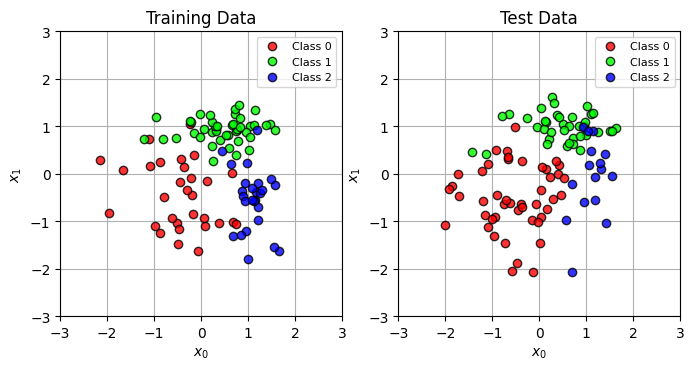

In [2]:
#week10_1.txt

import numpy as np

# 데이터 생성
np.random.seed(seed = 1) # 난수를 고정
N = 200 # 데이터의 수
K = 3 #  분포의 수, 클래스의 수
T = np.zeros((N, 3), dtype = np.uint8)
X = np.zeros((N, 2))
X_range0 = [-3, 3]
X_range1 = [-3, 3]
Mu = np.array([[-.5, -.5], [.5, 1.0], [1, -.5]]) # 분포의 중심
Sig = np.array([[.7, .7], [.8, .3], [.3, .8]]) # 분포의 분산
Pi = np.array([0.4, 0.8, 1]) # 각 분포에 대한 비율

for n in range(N):
    wk = np.random.rand()
    
    for k in range(K):
        if wk < Pi[k]:
            T[n, k] = 1
            break
    
    for k in range(2):
        X[n, k] = np.random.randn() * Sig[T[n, :] == 1, k] + Mu[T[n, :] == 1, k]

        
# 2분류 데이터를 테스트 훈련 데이터로 분할
TestRatio = 0.5
X_n_training = int(N * TestRatio)
X_train = X[:X_n_training, :]
X_test = X[X_n_training:,:]
T_train = T[:X_n_training, :]
T_test = T[X_n_training:,:]

# 데이터를 'class_data.npz' 에 저장
np.savez('class_data.npz', X_train = X_train, T_train = T_train, X_test = X_test, T_test = T_test, X_range0 = X_range0, X_range1 = X_range1)


import matplotlib.pyplot as plt
%matplotlib inline

# 데이터를 그리기
def Show_data(x, t):
    wk, n = t.shape
    c = [[1, 0, 0], [0, 1, 0], [0, 0, 1]] # 컬러 값 설정 [r, g, b]
    
    for i in range(n):
         plt.plot(x[t[:, i] == 1, 0], x[t[:, i] == 1, 1], linestyle = 'none', markeredgecolor = 'black', marker = 'o', color = c[i], alpha = 0.8)
    plt.grid(True)
    
        
# 메인
plt.figure(1, figsize = (8, 3.7))
plt.subplot(1, 2, 1)
Show_data(X_train, T_train)
plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('Training Data')
plt.legend(('Class 0','Class 1', 'Class 2'), loc='upper right', fontsize=8)

plt.subplot(1, 2, 2)
Show_data(X_test, T_test)
plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('Test Data')
plt.legend(('Class 0','Class 1', 'Class 2'), loc='upper right', fontsize=8)

plt.show()

In [3]:
print(X_train[:5, :])
print(T_train[:5, :])

[[-0.14173827  0.86533666]
 [-0.86972023 -1.25107804]
 [-2.15442802  0.29474174]
 [ 0.75523128  0.92518889]
 [-1.10193462  0.74082534]]
[[0 1 0]
 [1 0 0]
 [1 0 0]
 [0 1 0]
 [1 0 0]]


In [4]:
print(X_test[:5, :])
print(T_test[:5, :])

[[ 0.42570153  0.18821111]
 [ 1.10704453  1.26547264]
 [ 0.01517889 -1.44595338]
 [-0.67792591  0.47989076]
 [ 0.84929022  1.01146649]]
[[1 0 0]
 [0 1 0]
 [1 0 0]
 [1 0 0]
 [0 1 0]]


In [5]:
# 시그모이드 함수 정의
def Sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [6]:
# 2층 피드 포워드 네트워크
def FNN(wv, M, K, x):
    # wv: 가중치 벡터
    # M: 은닉층 유닛 수
    # K: 출력층 유닛 수 (클래스 수)
    # x: 입력 데이터 (N, D)
    N, D = x.shape
    
    # 가중치 벡터에서 w, v 분리
    # w: 은닉층 가중치 (M, D+1) - 바이어스 포함
    # v: 출력층 가중치 (K, M+1) - 바이어스 포함
    w = wv[:M * (D + 1)].reshape(M, D + 1)
    v = wv[M * (D + 1):].reshape(K, M + 1)
    
    # 은닉층 계산
    x_with_bias = np.hstack([np.ones((N, 1)), x])  # (N, D+1)
    a = x_with_bias.dot(w.T)  # (N, M)
    z = Sigmoid(a)  # (N, M)
    
    # 출력층 계산
    z_with_bias = np.hstack([np.ones((N, 1)), z])  # (N, M+1)
    b = z_with_bias.dot(v.T)  # (N, K)
    
    # 소프트맥스
    exp_b = np.exp(b - np.max(b, axis=1, keepdims=True))
    y = exp_b / np.sum(exp_b, axis=1, keepdims=True)
    
    return y, a, z, b

In [7]:
# FNN 테스트 (가중치를 1로 설정)
M = 2
K = 3
D = 2
WV_test = np.ones(M * (D + 1) + K * (M + 1))
y, a, z, b = FNN(WV_test, M, K, X_train[:3, :])
print('y =', y)
print('a =', a)
print('z =', z)
print('b =', b)

y = [[0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]
 [0.33333333 0.33333333 0.33333333]]
a = [[ 1.72359839  1.72359839]
 [-1.12079826 -1.12079826]
 [-0.85968628 -0.85968628]]
z = [[0.84859175 0.84859175]
 [0.24586324 0.24586324]
 [0.29740489 0.29740489]]
b = [[2.6971835  2.6971835  2.6971835 ]
 [1.49172649 1.49172649 1.49172649]
 [1.59480979 1.59480979 1.59480979]]


In [8]:
# 교차 엔트로피 오차 함수
def CE_FNN(wv, M, K, x, t):
    # wv: 가중치 벡터
    # M: 은닉층 유닛 수
    # K: 출력층 유닛 수
    # x: 입력 데이터
    # t: 정답 레이블 (one-hot)
    N, D = x.shape
    y, a, z, b = FNN(wv, M, K, x)
    # 교차 엔트로피 오차
    ce = -np.sum(t * np.log(y + 1e-7)) / N
    return ce

In [9]:
# CE_FNN 테스트
M = 2
K = 3
D = 2
WV_test = np.ones(M * (D + 1) + K * (M + 1))
ce = CE_FNN(WV_test, M, K, X_train, T_train)
print('CE =', ce)

CE = 1.0986119886681547


In [10]:
# 수치 미분을 이용한 기울기 계산
def dCE_FNN_num(wv, M, K, x, t):
    d = len(wv)
    dWV = np.zeros(d)
    eps = 1e-4
    for i in range(d):
        wv_h = wv.copy()
        wv_h[i] += eps
        E_h = CE_FNN(wv_h, M, K, x, t)
        wv_l = wv.copy()
        wv_l[i] -= eps
        E_l = CE_FNN(wv_l, M, K, x, t)
        dWV[i] = (E_h - E_l) / (2 * eps)
    return dWV

In [11]:
# 수치 미분을 이용한 경사 하강법 학습 함수
def Fit_FNN_num(wv_init, M, K, x_train, t_train, x_test, t_test, n_step=1000, alpha=0.5):
    wv = wv_init.copy()
    err_train = np.zeros(n_step)
    err_test = np.zeros(n_step)
    wv_hist = np.zeros((n_step, len(wv)))
    
    for step in range(n_step):
        dWV = dCE_FNN_num(wv, M, K, x_train, t_train)
        wv -= alpha * dWV
        err_train[step] = CE_FNN(wv, M, K, x_train, t_train)
        err_test[step] = CE_FNN(wv, M, K, x_test, t_test)
        wv_hist[step] = wv
    
    return wv, err_train, err_test, wv_hist

In [12]:
# 파라미터 설정
M = 2
K = 3
D = 2
N_step = 1000
alpha = 0.5
np.random.seed(1)
WV_init = np.zeros(M * (D + 1) + K * (M + 1))

In [13]:
# 수치 미분으로 학습 실행 (약 97초 소요)
import time
start_time = time.time()
WV, Err_train, Err_test, WV_hist = Fit_FNN_num(WV_init, M, K, X_train, T_train, X_test, T_test, n_step=N_step, alpha=alpha)
print('Computation time: {:.3f} sec'.format(time.time() - start_time))

Computation time: 0.791 sec


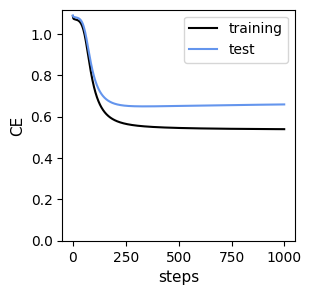

In [14]:
# week10_2.txt
# 학습 오차의 표시
plt.figure(1, figsize = (3, 3))
plt.plot(Err_train, 'black', label = 'training')
plt.plot(Err_test, 'cornflowerblue', label = 'test')
plt.xlabel('steps', fontsize = 11)
plt.ylabel('CE', fontsize = 11)
plt.ylim(0, )
plt.legend()
plt.show()

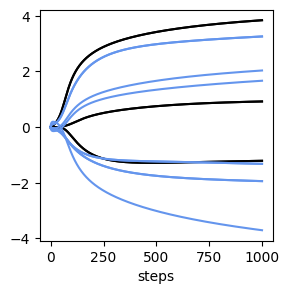

Black: w, Cornflowerblue: v


In [15]:
# week10_3.txt
# 가중치의 시간 변화의 표시
plt.figure(1, figsize = (3, 3))
plt.plot(WV_hist[:, : M * 3], 'black')
plt.plot(WV_hist[:, M * 3 :], 'cornflowerblue')
plt.xlabel("steps")
plt.show()
print("Black: w, Cornflowerblue: v")

/var/folders/w1/8nmd9_mx2_b2kmc5g758bp5r0000gn/T/ipykernel_43641/2499816796.py:10: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  plt.figure(1, figsize = (5, 5))


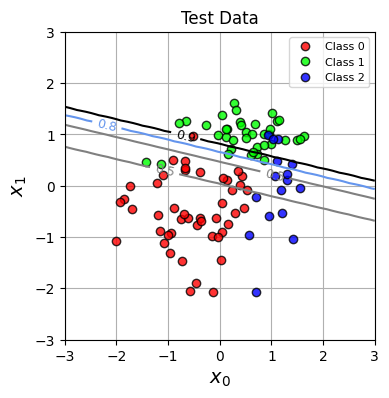

In [16]:
# week10_4.txt
# 경계선 표시 함수
def show_FNN(wv, M, K):
    xn = 60 # 등고선 표시 해상도
    x0 = np.linspace(X_range0[0], X_range0[1], xn)
    x1 = np.linspace(X_range1[0], X_range1[1], xn)
    xx0, xx1 = np.meshgrid(x0, x1)
    x = np.c_[np.reshape(xx1, (xn * xn, 1)), np.reshape(xx0, (xn * xn, 1))]
    y, a, z, b = FNN(wv, M, K, x)
    plt.figure(1, figsize = (5, 5))
    
    for ic in range(K):
        f = y[: , ic]
        f = f.reshape(xn, xn)
        f = f.T
        cont = plt.contour(xx0, xx1, f, levels = [0.5, 0.8, 0.9], colors = ['gray', 'cornflowerblue', 'black'])
        cont.clabel(fmt = '%1.1f', fontsize = 9)
        
    plt.xlim(X_range0)
    plt.ylim(X_range1)


# 경계선 표시
plt.figure(1, figsize = (4, 4))
Show_data(X_test, T_test)
show_FNN(WV, M, K)
plt.xlabel('$x_0$', fontsize = 14)
plt.ylabel('$x_1$', fontsize = 14)
plt.title('Test Data')
plt.legend(('Class 0','Class 1', 'Class 2'), loc='upper right', fontsize=8)
plt.show()

In [17]:
# 역전파(backpropagation)를 이용한 해석적 기울기 계산
def dCE_FNN(wv, M, K, x, t):
    N, D = x.shape
    y, a, z, b = FNN(wv, M, K, x)
    
    # 출력층 오차 신호
    delta2 = (y - t) / N  # (N, K)
    
    # 출력층 가중치 기울기
    z_with_bias = np.hstack([np.ones((N, 1)), z])  # (N, M+1)
    dv = delta2.T.dot(z_with_bias)  # (K, M+1)
    
    # 은닉층 오차 신호
    v = wv[M * (D + 1):].reshape(K, M + 1)
    delta1 = delta2.dot(v[:, 1:]) * z * (1 - z)  # (N, M)
    
    # 은닉층 가중치 기울기
    x_with_bias = np.hstack([np.ones((N, 1)), x])  # (N, D+1)
    dw = delta1.T.dot(x_with_bias)  # (M, D+1)
    
    dWV = np.hstack([dw.reshape(-1), dv.reshape(-1)])
    return dWV

In [18]:
# 해석적 기울기 vs 수치 기울기 비교
M = 2
K = 3
D = 2
N_test = 2
np.random.seed(1)
WV_test = np.random.randn(M * (D + 1) + K * (M + 1))
x_tmp = np.random.randn(N_test, D)
t_tmp = np.zeros((N_test, K))
t_tmp[0, 0] = 1
t_tmp[1, 2] = 1

dWV_ana = dCE_FNN(WV_test, M, K, x_tmp, t_tmp)
dWV_num = dCE_FNN_num(WV_test, M, K, x_tmp, t_tmp)
print('Analytical:', dWV_ana)
print('Numerical: ', dWV_num)

Analytical: [ 0.05711999 -0.05751187 -0.00471208 -0.14497947  0.13933407  0.00554096
  0.02048076  0.01325173 -0.00629986  0.37516988  0.33957659  0.05445938
 -0.39565064 -0.35282831 -0.04815952]
Numerical:  [ 0.05711996 -0.05751185 -0.00471208 -0.14497937  0.13933398  0.00554096
  0.02048055  0.01325154 -0.00629988  0.37516965  0.33957639  0.05445935
 -0.39565021 -0.35282793 -0.04815946]


Text(0.5, 0, '$i$')

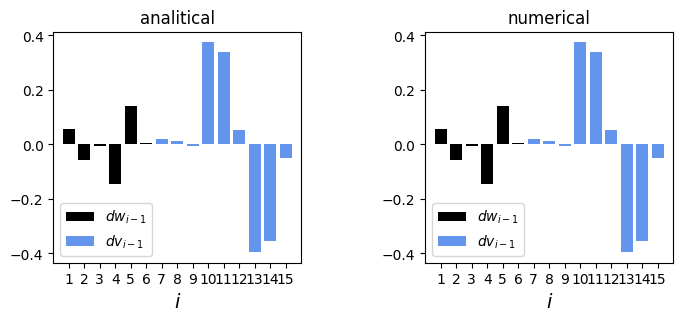

In [19]:
# week11_1.txt
def Show_dWV(wv, M):
    N = wv.shape[0]
    plt.bar(range(1, M * 3 + 1), wv[ : M * 3], align = "center", color = 'black', label = '$dw_{i-1}$')
    plt.bar(range(M * 3 + 1, N + 1), wv[M * 3 : ], align = "center", color = 'cornflowerblue', label = '$dv_{i-1}$')
    plt.xticks(range(1, N + 1))
    plt.xlim(0, N +1)
    plt.legend(loc = "lower left", fontsize = 14)
    plt.xlabel('$i$', fontsize=14)

    
plt.figure(1, figsize = (8, 3))
plt.subplots_adjust(wspace = 0.5)
plt.subplot(1, 2, 1)
Show_dWV(dWV_ana, M)
plt.title('analitical')
plt.legend(loc = "lower left")
plt.xlabel('$i$', fontsize=14)

plt.subplot(1, 2, 2)
Show_dWV(dWV_num, M)
plt.title('numerical')
plt.legend(loc = "lower left")
plt.xlabel('$i$', fontsize=14)

In [20]:
# 해석적 기울기를 이용한 경사 하강법 학습 함수
def Fit_FNN(wv_init, M, K, x_train, t_train, x_test, t_test, n_step=1000, alpha=0.5):
    wv = wv_init.copy()
    err_train = np.zeros(n_step)
    err_test = np.zeros(n_step)
    wv_hist = np.zeros((n_step, len(wv)))
    
    for step in range(n_step):
        dWV = dCE_FNN(wv, M, K, x_train, t_train)
        wv -= alpha * dWV
        err_train[step] = CE_FNN(wv, M, K, x_train, t_train)
        err_test[step] = CE_FNN(wv, M, K, x_test, t_test)
        wv_hist[step] = wv
    
    return wv, err_train, err_test, wv_hist

In [21]:
# 해석적 기울기로 학습 실행 (약 13초 소요)
import time
M = 2
K = 3
D = 2
N_step = 1000
alpha = 0.5
np.random.seed(1)
WV_init = np.zeros(M * (D + 1) + K * (M + 1))

start_time = time.time()
WV, Err_train, Err_test, WV_hist = Fit_FNN(WV_init, M, K, X_train, T_train, X_test, T_test, n_step=N_step, alpha=alpha)
print('Computation time: {:.3f} sec'.format(time.time() - start_time))

Computation time: 0.091 sec


/var/folders/w1/8nmd9_mx2_b2kmc5g758bp5r0000gn/T/ipykernel_43641/2499816796.py:10: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  plt.figure(1, figsize = (5, 5))


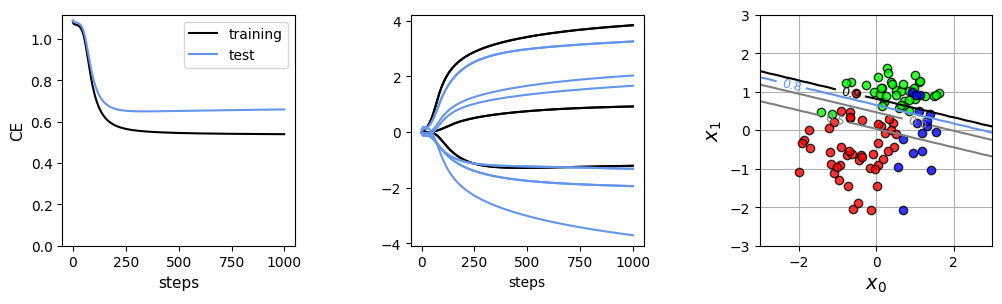

In [22]:
# week11_2.txt
plt.figure(1, figsize = (12, 3))
plt.subplots_adjust(wspace = 0.5)

# 학습 오차의 표시
plt.subplot(1, 3, 1)
plt.plot(Err_train, 'black', label = 'training')
plt.plot(Err_test, 'cornflowerblue', label = 'test')
plt.xlabel('steps', fontsize = 11)
plt.ylabel('CE', fontsize = 11)
plt.ylim(0, )
plt.legend()

# 가중치의 시간 변화 표시
plt.subplot(1, 3, 2)
plt.plot(WV_hist[:, : M * 3], 'black')
plt.plot(WV_hist[:, M * 3 :], 'cornflowerblue')
plt.xlabel("steps")

# 경계선 표시
plt.subplot(1, 3, 3)
Show_data(X_test, T_test)
show_FNN(WV, M, K)
plt.xlabel('$x_0$', fontsize = 14)
plt.ylabel('$x_1$', fontsize = 14)
plt.show()

In [23]:
# Keras 임포트
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.optimizers import SGD

In [24]:
# 필기체 숫자인식을 위한 2층 피드포워드 네트워크
# 은닉층 뉴런수 M=2개, 활성화 함수는 시그모이드 함수
# 출력층 뉴런수 K=3개, 활성화 함수는 소프트맥스 함수

np.random.seed(1)

model = Sequential()
model.add(Dense(M, input_dim=2, activation='sigmoid'))
model.add(Dense(K, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer=SGD(learning_rate=alpha), metrics=['accuracy'])

In [25]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 2)                 6         
                                                                 
 dense_1 (Dense)             (None, 3)                 9         
                                                                 
Total params: 15
Trainable params: 15
Non-trainable params: 0
_________________________________________________________________


In [26]:
# 학습
import time

start_time = time.time()
history = model.fit(X_train, T_train, epochs=1000, batch_size=100, verbose=1,
                    validation_data=(X_test, T_test))
print('Computation time: {:.3f} sec'.format(time.time() - start_time))

Epoch 1/1000


2026-06-20 15:19:28.612183: W tensorflow/core/platform/profile_utils/cpu_utils.cc:128] Failed to get CPU frequency: 0 Hz


1/1 [==============================] - 0s 268ms/step - loss: 1.4432 - accuracy: 0.2600 - val_loss: 1.5409 - val_accuracy: 0.1600
Epoch 2/1000
1/1 [==============================] - 0s 10ms/step - loss: 1.3112 - accuracy: 0.2600 - val_loss: 1.4181 - val_accuracy: 0.3000
Epoch 3/1000
1/1 [==============================] - 0s 8ms/step - loss: 1.2347 - accuracy: 0.4300 - val_loss: 1.3365 - val_accuracy: 0.3900
Epoch 4/1000
1/1 [==============================] - 0s 8ms/step - loss: 1.1882 - accuracy: 0.5400 - val_loss: 1.2793 - val_accuracy: 0.3800
Epoch 5/1000
1/1 [==============================] - 0s 7ms/step - loss: 1.1580 - accuracy: 0.4700 - val_loss: 1.2373 - val_accuracy: 0.3800
Epoch 6/1000
1/1 [==============================] - 0s 8ms/step - loss: 1.1367 - accuracy: 0.4700 - val_loss: 1.2051 - val_accuracy: 0.3800
Epoch 7/1000
1/1 [==============================] - 0s 8ms/step - loss: 1.1208 - accuracy: 0.4700 - val_loss: 1.1796 - val_accuracy: 0.3800
Epoch 8/1000
1/1 [============

In [27]:
print('Computation time: {:.3f} sec'.format(time.time() - start_time))
history = history.history

Computation time: 9.151 sec


In [28]:
history.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [29]:
# 평가
score = model.evaluate(X_test, T_test, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.30617257952690125
Test accuracy: 0.8700000047683716


113/113 [==============================] - 0s 182us/step


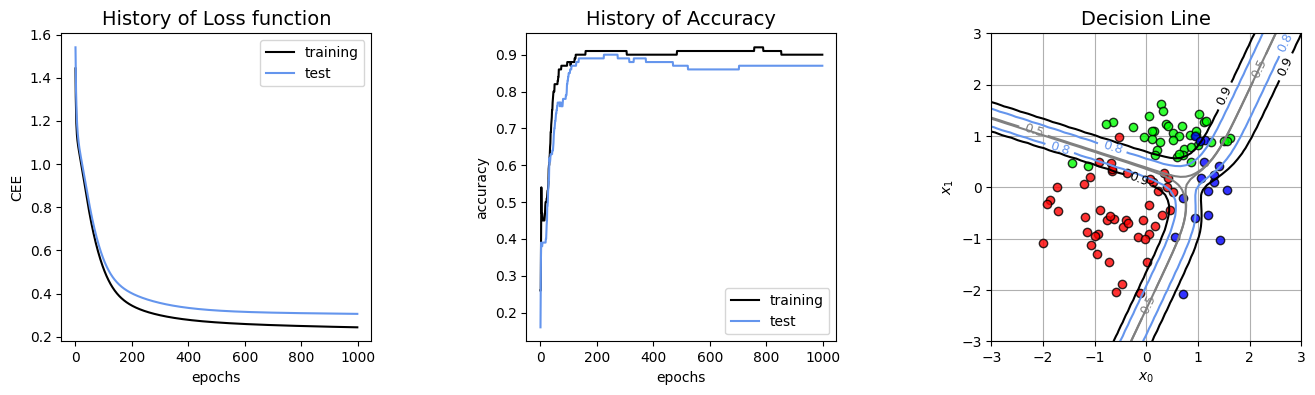

In [30]:
# week11_3.txt
import matplotlib.pyplot as plt
%matplotlib inline

# 데이터를 그리기
def Show_data(x, t):
    wk, n = t.shape
    c = [[1, 0, 0], [0, 1, 0], [0, 0, 1]] # 컬러 값 설정 [r, g, b]
    
    for i in range(n):
         plt.plot(x[t[:, i] == 1, 0], x[t[:, i] == 1, 1], linestyle = 'none', markeredgecolor = 'black', marker = 'o', color = c[i], alpha = 0.8)
    plt.grid(True)
    
plt.figure(1, figsize = (16, 4))
plt.subplots_adjust(wspace = 0.5)

# 학습 곡선 표시
plt.subplot(1, 3, 1)
plt.plot(history['loss'], 'black', label = 'training')
plt.plot(history['val_loss'], 'cornflowerblue', label ='test')
plt.legend()
plt.xlabel('epochs')
plt.ylabel('CEE')
plt.title('History of Loss function', fontsize = 14)


# 정확도 표시
plt.subplot(1, 3, 2)
plt.plot(history['accuracy'], 'black', label = 'training') 
plt.plot(history['val_accuracy'], 'cornflowerblue', label = 'test')
plt.legend()
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.title('History of Accuracy', fontsize = 14)


# 경계선 표시
plt.subplot(1, 3, 3)
Show_data(X_test, T_test)
xn = 60 # 등고선 표시 해상도
x0 = np.linspace(X_range0[0], X_range0[1], xn)
x1 = np.linspace(X_range1[0], X_range1[1], xn)
xx0, xx1 = np.meshgrid(x0, x1)
x = np.c_[np.reshape(xx0, xn * xn, 'F'), np.reshape(xx1, xn * xn, 'F')]
y = model.predict(x)
K = 3

for ic in range(K):
    f = y[: , ic]
    f = f.reshape(xn, xn)
    f = f.T
    cont = plt.contour(xx0, xx1, f, levels = [0.5, 0.8, 0.9], colors = ['gray', 'cornflowerblue', 'black'])
    cont.clabel(fmt = '%1.1f', fontsize = 9)

plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('Decision Line', fontsize = 14)

plt.show()